# Smart Crowd Density Monitoring — CSRNet Diagnostic & Corrected Inference

**Purpose:** Diagnose the previously trained CSRNet checkpoint and test it without retraining.

This notebook is designed around the CSRNet architecture in the original project notebook:
- VGG-16 frontend (`features[:23]`, three pooling stages)
- Six dilated convolution layers
- 1×1 density-map output layer
- ImageNet RGB normalization

**Important:** This notebook does not modify or overwrite your existing checkpoint. It first checks the checkpoint, then evaluates the model on ShanghaiTech Part B (if available), and finally allows testing a custom image.

## What this notebook can and cannot establish
- It can establish whether the checkpoint loads, whether predictions are numerically plausible, and how the model performs on labelled ShanghaiTech images.
- It cannot calculate the true error for an arbitrary photograph unless a reliable ground-truth head count or point annotation is available.
- It does not automatically combine YOLO and CSRNet. YOLO is an object detector; CSRNet is a density regressor. Their raw counts should not be switched using an arbitrary threshold.

## 1. Install / import dependencies
Run the install cell only if imports fail. Use the same Python environment where PyTorch and torchvision are installed.

In [1]:
# If required, uncomment and run:
# %pip install torch torchvision opencv-python pillow matplotlib numpy pandas scipy h5py ipywidgets

import os, glob, time, math, random, warnings
from pathlib import Path

import cv2
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat

import torch
import torch.nn as nn
from torchvision import models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 2050


## 2. Configure paths
Change these paths to match your folders. Keep your trained checkpoint in place; this notebook only reads it.

In [2]:
# Update these paths if your project folder layout is different.
PROJECT_DIR = Path.cwd()
CHECKPOINT_CANDIDATES = [
    PROJECT_DIR / "checkpoints" / "best_model_part_B.pth",
    PROJECT_DIR / "best_model_part_B.pth",
    PROJECT_DIR / "checkpoints" / "best_model.pth",
]

PART_B_TEST_DIR = PROJECT_DIR / "ShanghaiTech" / "part_B" / "test_data"
CUSTOM_IMAGE_PATH = ""  # Example: r"D:\CrowdProject\my_crowd_photo.jpg"

checkpoint_path = next((p for p in CHECKPOINT_CANDIDATES if p.exists()), None)
print("Project directory:", PROJECT_DIR)
print("Checkpoint found:", checkpoint_path if checkpoint_path else "NOT FOUND")
print("Part B test directory exists:", PART_B_TEST_DIR.exists())

Project directory: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM
Checkpoint found: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\best_model_part_B.pth
Part B test directory exists: True


## 3. Recreate the exact CSRNet architecture

The model definition below follows the architecture in your original notebook. Do not change layer names or dimensions when loading an existing checkpoint; otherwise, its weights may not match.

In [3]:
class CSRNet(nn.Module):
    def __init__(self, pretrained_frontend=False):
        super().__init__()
        # pretrained_frontend=False avoids downloading weights.
        # The trained checkpoint should supply the frontend weights.
        vgg = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT if pretrained_frontend else None
        )
        self.frontend = nn.Sequential(*list(vgg.features.children())[:23])

        self.backend = nn.Sequential(
            nn.Conv2d(512, 512, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 256, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, 3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
        )
        self.output_layer = nn.Conv2d(64, 1, kernel_size=1)

        self._initialize_backend_weights()

    def _initialize_backend_weights(self):
        for module in self.backend.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.normal_(module.weight, std=0.01)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
        nn.init.normal_(self.output_layer.weight, std=0.01)
        if self.output_layer.bias is not None:
            nn.init.constant_(self.output_layer.bias, 0)

    def forward(self, x):
        x = self.frontend(x)
        x = self.backend(x)
        return self.output_layer(x)

model = CSRNet(pretrained_frontend=False).to(device)
print("CSRNet instantiated.")

CSRNet instantiated.


## 4. Load and verify the trained checkpoint

This loader supports a plain `state_dict` and common checkpoint dictionaries containing `state_dict` or `model_state_dict`. It uses strict loading so architecture mismatches are not silently ignored.

In [4]:
def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in checkpoint and isinstance(checkpoint[key], dict):
                return checkpoint[key]
        # Plain state_dict: tensor values under parameter names
        if checkpoint and all(torch.is_tensor(v) for v in checkpoint.values()):
            return checkpoint
    raise ValueError("Could not find a model state_dict in this checkpoint.")

if checkpoint_path is None:
    raise FileNotFoundError(
        "No checkpoint was found. Put your trained .pth file in the checkpoints folder "
        "or edit CHECKPOINT_CANDIDATES in Section 2."
    )

try:
    checkpoint_obj = torch.load(checkpoint_path, map_location=device, weights_only=True)
except TypeError:
    checkpoint_obj = torch.load(checkpoint_path, map_location=device)

state_dict = extract_state_dict(checkpoint_obj)

# Handle checkpoints saved from nn.DataParallel.
if any(k.startswith("module.") for k in state_dict):
    state_dict = {k.removeprefix("module."): v for k, v in state_dict.items()}

load_result = model.load_state_dict(state_dict, strict=True)
model.eval()

print("Checkpoint loaded successfully:", checkpoint_path)
print("Strict load result:", load_result)
print("Parameter tensors:", len(state_dict))
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Checkpoint loaded successfully: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\best_model_part_B.pth
Strict load result: <All keys matched successfully>
Parameter tensors: 34
Total parameters: 16263489


## 5. Corrected image preprocessing and inference

The training notebook normalized RGB images using ImageNet mean/std and did not resize the training image. This inference function follows that convention.

It pads only the bottom/right to a multiple of 8 so the three VGG pooling stages produce a clean output size. It does **not** resize the image, because resizing can change the learned scale/perspective distribution. The padding is applied after normalization (zero means the normalized ImageNet mean).

In [5]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def read_rgb_image(image_path):
    image = Image.open(image_path).convert("RGB")
    return np.asarray(image)

def preprocess_rgb(rgb):
    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError(f"Expected HxWx3 RGB image, got {rgb.shape}")
    if rgb.dtype != np.uint8:
        rgb = np.clip(rgb, 0, 255).astype(np.uint8)

    x = rgb.astype(np.float32) / 255.0
    x = (x - IMAGENET_MEAN) / IMAGENET_STD

    h, w = x.shape[:2]
    pad_h = (-h) % 8
    pad_w = (-w) % 8
    if pad_h or pad_w:
        x = np.pad(x, ((0, pad_h), (0, pad_w), (0, 0)),
                   mode="constant", constant_values=0)

    tensor = torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0).float()
    return tensor.to(device), (h, w), (pad_h, pad_w)

@torch.inference_mode()
def predict_csrnet(rgb):
    model.eval()
    tensor, original_hw, padding = preprocess_rgb(rgb)

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    output = model(tensor)
    if device.type == "cuda":
        torch.cuda.synchronize()
    latency_ms = (time.perf_counter() - start) * 1000

    density = output[0, 0].detach().float().cpu().numpy()
    raw_integral = float(density.sum())
    # CSRNet's final layer is linear; small negative values can occur.
    # Report raw integral and a non-negative operational count separately.
    operational_count = max(0.0, raw_integral)

    return {
        "count": operational_count,
        "raw_integral": raw_integral,
        "density": density,
        "latency_ms": latency_ms,
        "output_shape": tuple(density.shape),
        "input_shape": tuple(rgb.shape[:2]),
        "padding": padding,
    }

print("Inference functions ready.")

Inference functions ready.


## 6. Run a single-image sanity check

Start with a ShanghaiTech Part B image, if the dataset is available. The count is the **sum of the predicted density map**, not the number of bright heatmap pixels.

In [6]:
part_b_images = sorted((PART_B_TEST_DIR / "images").glob("*.jpg")) if (PART_B_TEST_DIR / "images").exists() else []
if part_b_images:
    sanity_image_path = part_b_images[0]
    sanity_rgb = read_rgb_image(sanity_image_path)
    sanity_result = predict_csrnet(sanity_rgb)
    print("Image:", sanity_image_path)
    print("Image dimensions:", sanity_result["input_shape"])
    print("Output density dimensions:", sanity_result["output_shape"])
    print("Raw density integral:", round(sanity_result["raw_integral"], 3))
    print("Non-negative predicted count:", round(sanity_result["count"], 3))
    print("Latency (ms):", round(sanity_result["latency_ms"], 2))
else:
    print("Part B images not found. You can still test a custom image in Section 10.")

Image: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\ShanghaiTech\part_B\test_data\images\IMG_1.jpg
Image dimensions: (768, 1024)
Output density dimensions: (96, 128)
Raw density integral: 37.683
Non-negative predicted count: 37.683
Latency (ms): 585.61


## 7. Visualize density correctly

The heatmap is normalized **for display only**. Its colors are not confidence scores, and its normalized pixel values must never be summed to obtain the count.

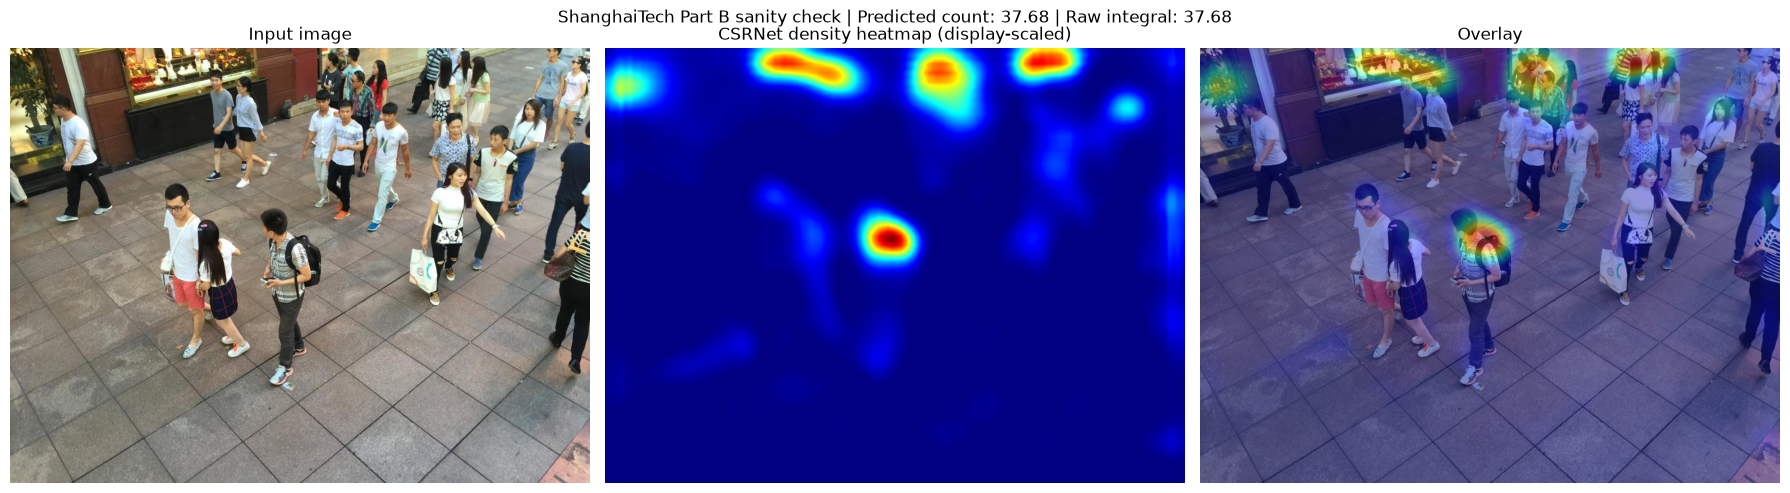

In [7]:
def show_prediction(rgb, result, title="CSRNet prediction"):
    density = result["density"]
    h, w = rgb.shape[:2]

    # Resize only for overlay visualization, not for count computation.
    density_full = cv2.resize(density, (w, h), interpolation=cv2.INTER_LINEAR)
    density_display = np.maximum(density_full, 0)

    if np.max(density_display) > 0:
        heat_u8 = cv2.normalize(density_display, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    else:
        heat_u8 = np.zeros((h, w), dtype=np.uint8)

    heat_bgr = cv2.applyColorMap(heat_u8, cv2.COLORMAP_JET)
    heat_rgb = cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(rgb, 0.58, heat_rgb, 0.42, 0)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(rgb)
    ax[0].set_title("Input image")
    ax[1].imshow(heat_rgb)
    ax[1].set_title("CSRNet density heatmap (display-scaled)")
    ax[2].imshow(overlay)
    ax[2].set_title("Overlay")
    for a in ax:
        a.axis("off")
    fig.suptitle(
        f"{title} | Predicted count: {result['count']:.2f} | "
        f"Raw integral: {result['raw_integral']:.2f}"
    )
    plt.tight_layout()
    plt.show()

if part_b_images:
    show_prediction(sanity_rgb, sanity_result, "ShanghaiTech Part B sanity check")

## 8. Ground-truth count reader and validation benchmark

For ShanghaiTech, the `.mat` point annotations are the preferred source of the actual count. If the `.mat` file is absent, this code falls back to summing a matching `.h5` density map.

Do not compare a prediction against a density map generated with a different scaling convention.

In [8]:
def find_mat_for_image(image_path):
    p = Path(image_path)
    # Standard ShanghaiTech layout: test_data/images/IMG_1.jpg
    gt_dir = p.parent.parent / "ground-truth"
    mat_path = gt_dir / f"GT_{p.stem}.mat"
    return mat_path if mat_path.exists() else None

def read_mat_point_count(mat_path):
    mat = loadmat(str(mat_path))
    if "image_info" not in mat:
        raise KeyError(f"'image_info' not found in {mat_path}")
    points = mat["image_info"][0, 0][0, 0][0]
    return int(len(points))

def get_ground_truth_count(image_path):
    mat_path = find_mat_for_image(image_path)
    if mat_path:
        return float(read_mat_point_count(mat_path)), f"MAT points: {mat_path.name}"

    h5_path = Path(image_path).with_suffix(".h5")
    if h5_path.exists():
        with h5py.File(h5_path, "r") as hf:
            key = "density" if "density" in hf else list(hf.keys())[0]
            return float(np.asarray(hf[key]).sum()), f"H5 sum: {h5_path.name}"

    return None, "No annotation found"

def evaluate_image_list(image_paths, max_images=None):
    paths = list(image_paths)
    if max_images is not None:
        paths = paths[:max_images]

    rows = []
    for idx, path in enumerate(paths, start=1):
        try:
            rgb = read_rgb_image(path)
            pred = predict_csrnet(rgb)
            gt, gt_source = get_ground_truth_count(path)
            error = abs(pred["count"] - gt) if gt is not None else np.nan
            rows.append({
                "image": Path(path).name,
                "ground_truth": gt,
                "prediction": pred["count"],
                "absolute_error": error,
                "relative_error_%": (100 * error / max(gt, 1)) if gt is not None else np.nan,
                "raw_integral": pred["raw_integral"],
                "latency_ms": pred["latency_ms"],
                "gt_source": gt_source,
            })
        except Exception as exc:
            print(f"Skipped {path}: {exc}")

        if idx % 25 == 0:
            print(f"Processed {idx}/{len(paths)}")

    return pd.DataFrame(rows)

if part_b_images:
    # Run on all Part B test images for a meaningful MAE, not just one example.
    df_val = evaluate_image_list(part_b_images)
    display(df_val.head(10))

    valid = df_val.dropna(subset=["ground_truth", "absolute_error"])
    if len(valid):
        mae = valid["absolute_error"].mean()
        rmse = np.sqrt(np.mean((valid["prediction"] - valid["ground_truth"]) ** 2))
        print(f"Evaluated images: {len(valid)}")
        print(f"MAE:  {mae:.3f} people")
        print(f"RMSE: {rmse:.3f} people")
        print(f"Mean relative error: {valid['relative_error_%'].mean():.2f}%")
    else:
        print("No ground-truth annotations were found. Check your dataset folder structure.")
else:
    print("Part B test images unavailable; validation benchmark skipped.")

Processed 25/316
Processed 50/316
Processed 75/316
Processed 100/316
Processed 125/316
Processed 150/316
Processed 175/316
Processed 200/316
Processed 225/316
Processed 250/316
Processed 275/316
Processed 300/316


,image,ground_truth,prediction,absolute_error,relative_error_%,raw_integral,latency_ms,gt_source
0,IMG_1.jpg,23.0,37.683472,14.683472,63.841181,37.683472,161.4853,MAT points: GT_IMG_1.mat
1,IMG_10.jpg,181.0,173.172836,7.827164,4.324400,173.172836,160.0582,MAT points: GT_IMG_10.mat
2,IMG_100.jpg,157.0,138.157837,18.842163,12.001378,138.157837,162.0666,MAT points: GT_IMG_100.mat
3,IMG_101.jpg,37.0,32.910381,4.089619,11.053023,32.910381,158.0185,MAT points: GT_IMG_101.mat
4,IMG_102.jpg,70.0,58.275429,11.724571,16.749387,58.275429,162.3912,MAT points: GT_IMG_102.mat
5,IMG_103.jpg,57.0,111.615082,54.615082,95.815933,111.615082,159.3986,MAT points: GT_IMG_103.mat
6,IMG_104.jpg,44.0,81.518799,37.518799,85.269997,81.518799,159.4889,MAT points: GT_IMG_104.mat
7,IMG_105.jpg,227.0,203.961914,23.038086,10.148937,203.961914,158.6248,MAT points: GT_IMG_105.mat
8,IMG_106.jpg,165.0,143.128647,21.871353,13.255366,143.128647,160.7530,MAT points: GT_IMG_106.mat
9,IMG_107.jpg,476.0,387.619385,88.380615,18.567356,387.619385,161.6600,MAT points: GT_IMG_107.mat


Evaluated images: 316
MAE:  28.903 people
RMSE: 41.333 people
Mean relative error: 30.71%


## 9. Inspect the worst validation examples

Large errors may indicate a checkpoint issue, preprocessing mismatch, dataset mismatch, or a small number of difficult frames. Review these images before changing the model.

,image,ground_truth,prediction,absolute_error,relative_error_%,raw_integral,latency_ms,gt_source
295,IMG_80.jpg,470.0,276.175720,193.824280,41.239208,276.175720,161.6315,MAT points: GT_IMG_80.mat
289,IMG_75.jpg,539.0,360.457794,178.542206,33.124714,360.457794,159.4666,MAT points: GT_IMG_75.mat
251,IMG_40.jpg,331.0,185.642365,145.357635,43.914694,185.642365,160.0211,MAT points: GT_IMG_40.mat
61,IMG_154.jpg,465.0,333.963165,131.036835,28.179964,333.963165,160.2436,MAT points: GT_IMG_154.mat
23,IMG_12.jpg,513.0,386.753601,126.246399,24.609434,386.753601,162.0221,MAT points: GT_IMG_12.mat
140,IMG_225.jpg,265.0,379.083954,114.083954,43.050549,379.083954,160.2697,MAT points: GT_IMG_225.mat
159,IMG_242.jpg,177.0,291.009552,114.009552,64.412176,291.009552,159.6974,MAT points: GT_IMG_242.mat
133,IMG_219.jpg,450.0,336.696991,113.303009,25.178446,336.696991,162.4210,MAT points: GT_IMG_219.mat
55,IMG_149.jpg,147.0,259.833160,112.833160,76.757252,259.833160,162.4697,MAT points: GT_IMG_149.mat
11,IMG_109.jpg,316.0,204.214050,111.785950,35.375301,204.214050,160.4440,MAT points: GT_IMG_109.mat


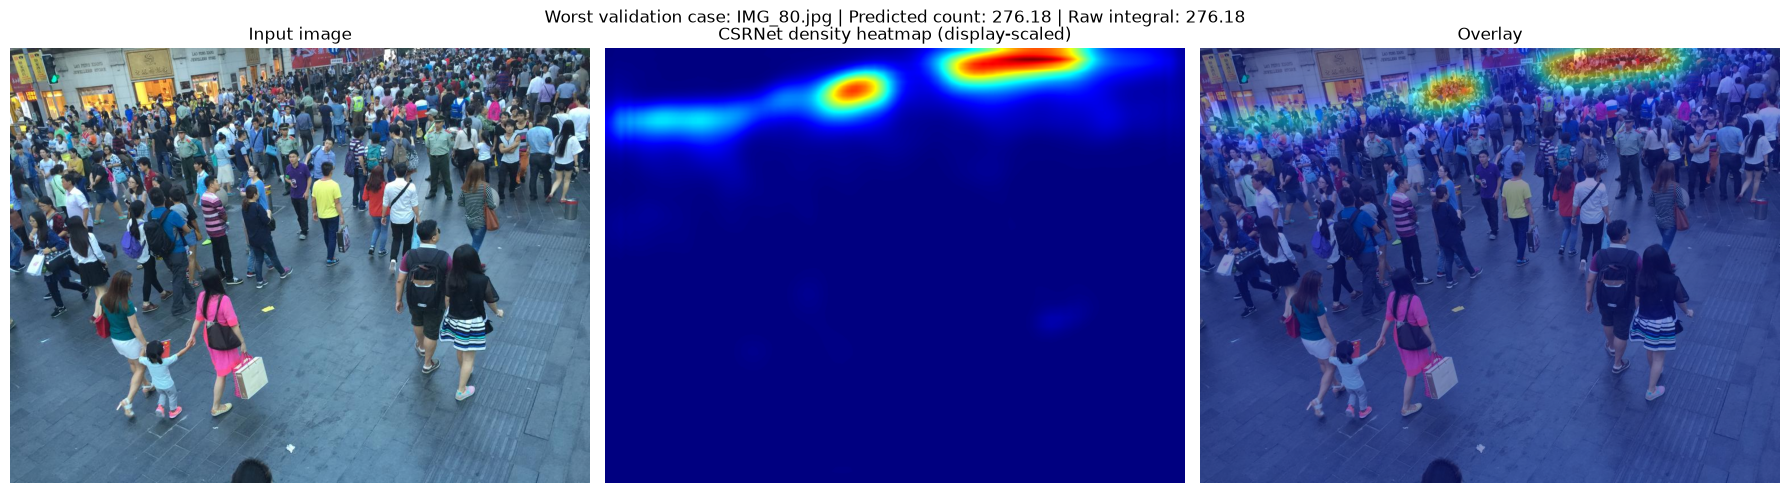

Ground truth: (470.0, 'MAT points: GT_IMG_80.mat')


In [9]:
if 'df_val' in globals() and not df_val.empty:
    valid = df_val.dropna(subset=["absolute_error"]).sort_values("absolute_error", ascending=False)
    display(valid.head(15))

    if len(valid):
        worst_name = valid.iloc[0]["image"]
        worst_path = next((p for p in part_b_images if Path(p).name == worst_name), None)
        if worst_path:
            worst_rgb = read_rgb_image(worst_path)
            worst_result = predict_csrnet(worst_rgb)
            show_prediction(worst_rgb, worst_result, f"Worst validation case: {worst_name}")
            print("Ground truth:", get_ground_truth_count(worst_path))

## 10. Test your own photograph

Set `CUSTOM_IMAGE_PATH` in Section 2, then run this cell. If the photograph is not from ShanghaiTech and has no annotations, the notebook can show a prediction but cannot prove whether it is correct.

In [10]:
if CUSTOM_IMAGE_PATH and Path(CUSTOM_IMAGE_PATH).exists():
    custom_rgb = read_rgb_image(CUSTOM_IMAGE_PATH)
    custom_result = predict_csrnet(custom_rgb)
    show_prediction(custom_rgb, custom_result, Path(CUSTOM_IMAGE_PATH).name)
    print("Predicted count:", round(custom_result["count"], 2))
    print("Raw density integral:", round(custom_result["raw_integral"], 2))
    print("Latency (ms):", round(custom_result["latency_ms"], 2))
    print("Image dimensions:", custom_result["input_shape"])
else:
    print("Set CUSTOM_IMAGE_PATH in Section 2 to your image file, then rerun this cell.")

Set CUSTOM_IMAGE_PATH in Section 2 to your image file, then rerun this cell.


## 11. Optional count calibration — only after validation

If the model consistently overestimates or underestimates on the **same validation distribution**, a simple scalar calibration can be estimated from validation predictions. This does not fix spatial errors or domain shift, and it must not be fitted on the custom test photograph.

Use the calibrated count only as an experimental comparison. Report raw CSRNet MAE and calibrated MAE separately.

In [11]:
if 'df_val' in globals() and not df_val.empty:
    cal = df_val.dropna(subset=["ground_truth", "prediction"]).copy()
    denominator = float(np.dot(cal["prediction"], cal["prediction"]))
    if len(cal) >= 10 and denominator > 1e-8:
        scale = float(np.dot(cal["prediction"], cal["ground_truth"]) / denominator)
        scale = max(0.0, scale)
        cal["calibrated_prediction"] = scale * cal["prediction"]
        raw_mae = np.mean(np.abs(cal["prediction"] - cal["ground_truth"]))
        calibrated_mae = np.mean(np.abs(cal["calibrated_prediction"] - cal["ground_truth"]))
        print(f"Validation-derived scale: {scale:.4f}")
        print(f"Raw validation MAE: {raw_mae:.3f}")
        print(f"Calibrated validation MAE: {calibrated_mae:.3f}")
        print("Do not treat this as an independent test result; the scale was fitted on this validation set.")
    else:
        print("Need at least 10 annotated validation images to estimate a basic scale.")

Validation-derived scale: 1.0127
Raw validation MAE: 28.903
Calibrated validation MAE: 29.090
Do not treat this as an independent test result; the scale was fitted on this validation set.


## 12. Optional YOLO comparison (not automatic switching)

YOLO can be useful for visible, separated people, but dense occlusion can cause missed detections. Compare YOLO and CSRNet side by side; do not choose the smaller count or switch at an arbitrary threshold. If using a hybrid system, learn and validate the routing rule on labelled data from the intended camera environment.

In [12]:
# Optional. Install with: %pip install ultralytics
RUN_YOLO_COMPARISON = False
YOLO_WEIGHTS = "yolov8n.pt"
YOLO_CONFIDENCE = 0.25

if RUN_YOLO_COMPARISON:
    from ultralytics import YOLO
    yolo = YOLO(YOLO_WEIGHTS)
    if CUSTOM_IMAGE_PATH and Path(CUSTOM_IMAGE_PATH).exists():
        yolo_result = yolo(CUSTOM_IMAGE_PATH, classes=[0], conf=YOLO_CONFIDENCE, verbose=False)[0]
        yolo_count = 0 if yolo_result.boxes is None else len(yolo_result.boxes)
        print("YOLO person detections:", yolo_count)
        print("CSRNet density count:", round(custom_result["count"], 2) if 'custom_result' in globals() else "Run Section 10 first")
    else:
        print("Set CUSTOM_IMAGE_PATH and run Section 10 before YOLO comparison.")
else:
    print("YOLO comparison disabled. Set RUN_YOLO_COMPARISON=True only if ultralytics is installed.")

YOLO comparison disabled. Set RUN_YOLO_COMPARISON=True only if ultralytics is installed.


## 13. How to interpret the results and what to do next

1. **Checkpoint fails strict loading:** verify you selected the exact `.pth` file produced by this CSRNet architecture. Do not use a YOLO `.pt` file here.
2. **Part B validation MAE is also very high:** investigate checkpoint provenance, training completion, annotation/density-map generation, and whether the checkpoint was saved as the best model. Do not retrain until these checks are complete.
3. **Part B validation is reasonable but your own image is poor:** this is likely a domain/generalization issue. Collect labelled images from the target camera/location and fine-tune or calibrate using a training/validation split from that domain.
4. **Only the heatmap looks strange:** remember that heatmap colors are display-normalized. Count is computed from the unnormalized density output.
5. **Do not use the result for real emergency actuation yet.** Validate on representative camera footage and set safety thresholds from the physical site's capacity and risk assessment.

### What to send back for the next debugging step
- The checkpoint loading output from Section 4.
- The Part B MAE/RMSE output from Section 8.
- The worst-case image output from Section 9.
- The predicted count and image dimensions from Section 10.
- If possible, the exact checkpoint filename and the training log / best validation MAE from the earlier run.